# Titanic XGB: Feature Importance and Explainability

This notebook aims to understand which features influence the predictions of my XGBoost model from 'titanic_v3_xgboost.ipynb'.

We will explore three methods:
1. Built-in feature importance
2. Permutation importance
3. SHAP explanations

## 01. Load data

In [1]:
# Import Modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Set Up Complete")

# Load Data
titanic = pd.read_csv("train.csv")
titanic.head()

Set Up Complete


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 02. Train/validation split, Basic Preprocessing Pipeline

Drop Passenger ID, Name, Ticket, Cabin columns
Separate X and y
Train/validation split
Fit preprocessing pipeline only on X_train

In [2]:
# Drop Passenger ID, Name, Ticket, Cabin
titanic_v2 = titanic.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

# Train/Test Split
from sklearn.model_selection import train_test_split
X = titanic_v2.drop(columns=["Survived"])
y = titanic_v2["Survived"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Separate numerical and categorical columns
numerical_columns = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_columns = ["Sex", "Embarked"]

# Import necessary libraries
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Build preprocessing
numerical_transformer = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("encoder", OneHotEncoder())])

# Combine both
preprocessing = ColumnTransformer([("num", numerical_transformer, numerical_columns),
                                   ("cat", categorical_transformer, categorical_columns)],
                                   remainder = 'passthrough')

## 03. Fit XGBoost model

In [4]:
from xgboost import XGBClassifier

# Build XGB Pipeline
xgb_model = Pipeline([("preprocessing", preprocessing), ("classifier", XGBClassifier(n_estimators=10, max_depth=7, learning_rate=0.3, random_state=42, eval_metric="logloss"))])

# Train model
xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining colum

## 04. Built-in Feature Importance

First, we will examine the feature importance values provided by XGBoost. These values help identify features that the model uses when building its decision trees. 

In [7]:
# Extract feature importance values

# Get the fitted preprocessing step
fitted_preprocessing = xgb_model.named_steps["preprocessing"]

# Get the fitted XGBoost model
fitted_xgb = xgb_model.named_steps["classifier"]

# Get the feature names after preprocessing
feature_names = fitted_preprocessing.get_feature_names_out()

# Pair feature names with their importance values (*feature_importances_ returns XGB's built-in importance scores)
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": fitted_xgb.feature_importances_})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
5,cat__Sex_female,0.707825
0,num__Pclass,0.137581
2,num__SibSp,0.041252
1,num__Age,0.024731
4,num__Fare,0.021678
7,cat__Embarked_C,0.020016
9,cat__Embarked_S,0.018010
8,cat__Embarked_Q,0.014655
3,num__Parch,0.014252
6,cat__Sex_male,0.000000


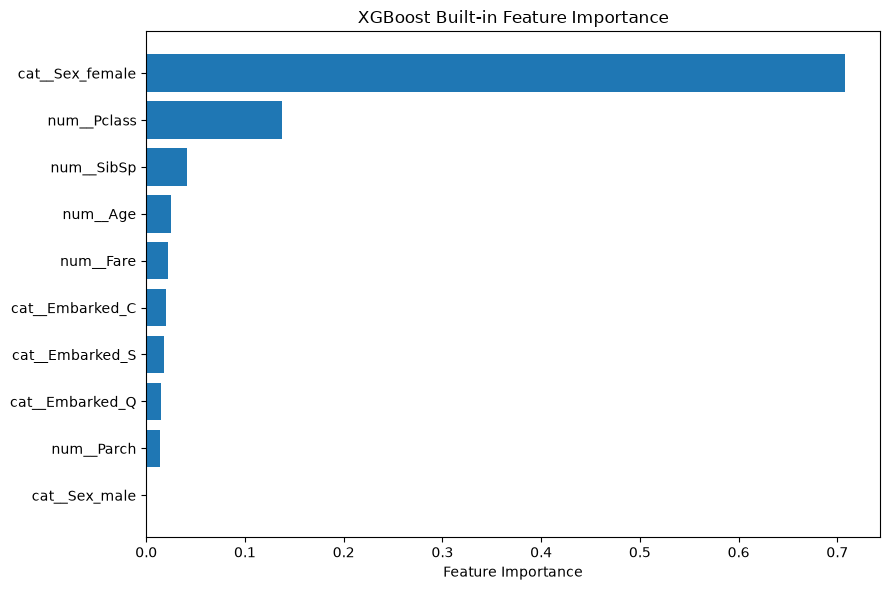

In [8]:
# Visualize feature importance using bar plot
importance_plot = importance_df.sort_values(by="Importance", ascending=True)

plt.figure(figsize=(9, 6))
plt.barh(importance_plot["Feature"], importance_plot["Importance"])
plt.xlabel("Feature Importance")
plt.title("XGBoost Built-in Feature Importance")
plt.tight_layout()
plt.show()

### Interpretation of XGB's built-in feature importance

The built-in XGBoost importance scores identifies Sex_female as the dominant feature, followed by Pclass. Age, family-related features, fare, and embarkation point have smaller importance scores in this fitted model.

However, built-in importance does not show whether a feature increases or decreases probability of survival. These results will be compared to permutation importance and SHAP to gain a more complete understanding of the model's predictions.

## 05. Permutation Importance

Permutation importance measures how much a model's performance decreases when the values of one feature are randomly shuffled. 

If shuffling a feature reduces accuracy substantially, that feature is useful to the model's predictions.

In [10]:
from sklearn.inspection import permutation_importance

# Obtain permutation importance, shuffling each feature 10 times and measuring the decrease in accuracy
permutation_results = permutation_importance(xgb_model, X_valid, y_valid, scoring="accuracy", n_repeats=10, random_state=42)

# Pair feature names with their permutation importance values
permutation_df = pd.DataFrame({"Feature": X_valid.columns, "Importance": permutation_results.importances_mean, "Std": permutation_results.importances_std})
permutation_df = permutation_df.sort_values(by="Importance", ascending=False)
permutation_df

,Feature,Importance,Std
1,Sex,0.193855,0.031310
0,Pclass,0.122346,0.018604
2,Age,0.056983,0.018154
5,Fare,0.054749,0.019481
6,Embarked,0.031285,0.011229
3,SibSp,0.006704,0.003352
4,Parch,0.000000,0.000000


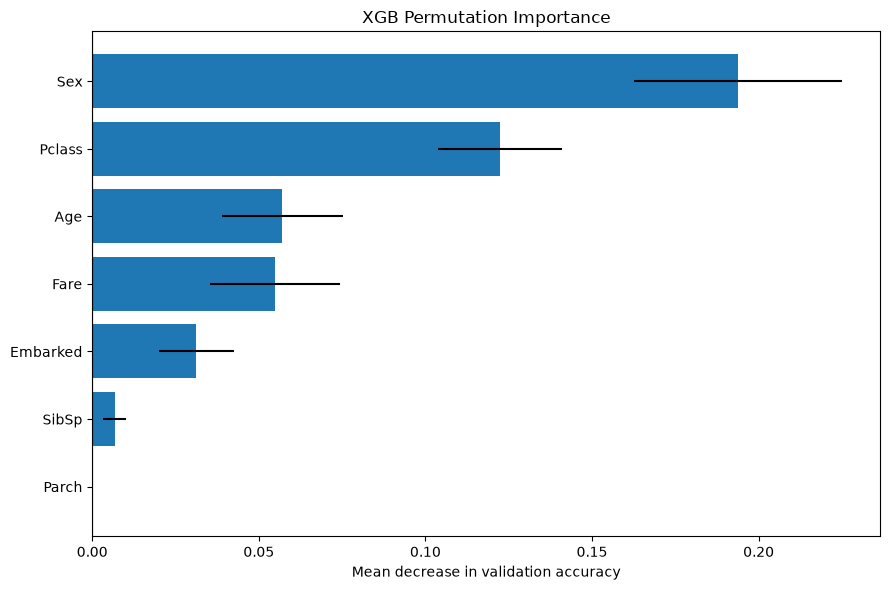

In [13]:
# Visualize permutation importance using bar plot
permutation_plot = permutation_df.sort_values(by="Importance", ascending=True)

plt.figure(figsize=(9,6))
plt.barh(permutation_plot["Feature"], permutation_plot["Importance"], xerr=permutation_plot["Std"])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Mean decrease in validation accuracy")
plt.title("XGB Permutation Importance")
plt.tight_layout()
plt.show()

### Interpretation of XGB's permutation importance

Both built-in feature importance and permutation importance agree on the top features: Sex and Pclass rank highest in both. This consistency increases our confidence that these features are important to this model. 

Age and Fare also have meaningful importance, despite their lower built-in scores. 

Parch has zero measured importance on this validation set, suggesting that shuffling it did not affect accuracy in these experiments. 

These results describe this fitted model's predictive behaviour, not causal effects. The rankings may also vary with the validation sample and correlated features. 

## 06. SHAP

SHAP (SHapley Additive exPlanation) estimates how each feature contributes to a model's prediction -- how each feature pushes a prediction higher or lower. 

In this titanic dataset, a positive SHAP value pushes the prediction towards survival, while a negative SHAP value pushes the prediction away from survival. A larger absolute value shows a stronger contribution to that prediction.

We will use a SHAP summary plot to examine feature contributions across passengers, followed by a waterfall plot to explain individual predictions.

In [ ]:
# Install SHAP library in this notebook env
%pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 12.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


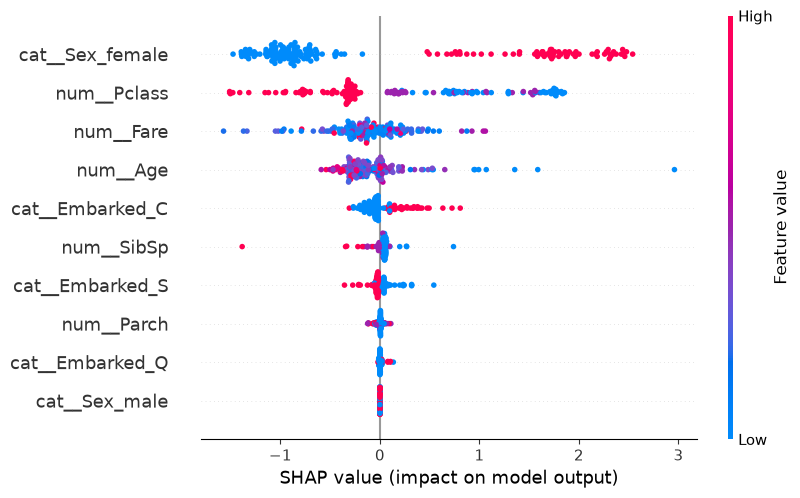

In [ ]:
import shap

# Transform validation data using fitted preprocessing pipeline
X_valid_transformed = xgb_model.named_steps["preprocessing"].transform(X_valid)

# Get feature names after preprocessing
feature_names = xgb_model.named_steps["preprocessing"].get_feature_names_out()

# Convert transformed data into DataFrame for SHAP
X_valid_transformed_df = pd.DataFrame(X_valid_transformed, columns=feature_names, index=X_valid.index)

# Explain the fitted XGB model using TreeExplainer (designed for tree-based models like XGB)
fitted_xgb = xgb_model.named_steps["classifier"]
explainer = shap.TreeExplainer(fitted_xgb)
shap_values = explainer(X_valid_transformed_df)

# Create SHAP summary plot
shap.plots.beeswarm(shap_values)

### 6.1 Explain 1 passenger with a waterfall plot

The summary plot above shows patterns across many passengers, with each dot representing 1 passenger.

A waterfall plot allows us to examine 1 prediction in detail. 

Passenger Index: 709
Actual Survival: 1
Predicted Survival: 0


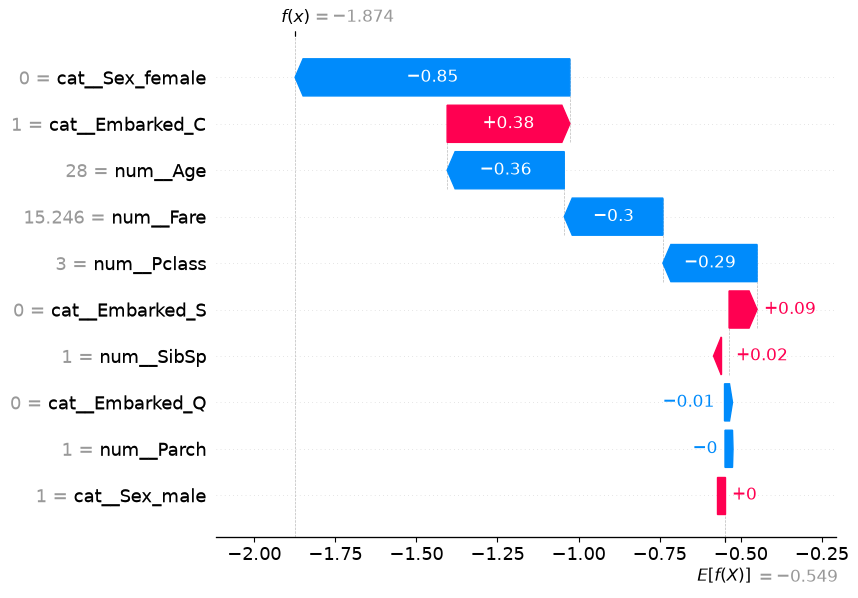

In [ ]:
# Select first passenger in validation set
passenger_index = 0  # Change this index to visualize different passengers

print("Passenger Index:", X_valid.index[passenger_index])
print("Actual Survival:", y_valid.iloc[passenger_index])
print("Predicted Survival:", xgb_model.predict(X_valid.iloc[[passenger_index]])[0])

# Plot that passenger's SHAP values using waterfall plot
shap.plots.waterfall(shap_values[passenger_index])

For this passenger, the strongest contribution was the negative SHAP value for Sex_female. The positive contribution from Embarked_C partly offsets the negative contributions from Age, Fare, and Pclass. 

## 07. Conclusion

| Method | Key Takeaway |
| ------ |  ----------: |
| Built-in importance |Sex_female dominates the model's tree-based importance scores|
| Permutation importance|Shuffling Sex and Pclass hurts validation accuracy most|
| SHAP |Sex and Pclass matter across passengers, while feature contributions can vary by individual|

Built-in importance, permutation importance, and SHAP consistently identified Sex and Pclass as important features in my XGBoost model. Permutation importance also highlighted the predictive value of Age and Fare, while SHAP adds information about the direction of individual contributions.

Feature importance and individual prediction explanations answer different questions. SHAP helps interpret model behaviour, but these explanations do not establish causation or prove that a model is clinically reliable.
